# 01 · End-member mixing analysis, EMMA (Figure 11, SM10, SM11, SM12)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**

Quantifies the contributions of three recharge end-members to groundwater with a three-end-member mass balance on two conservative tracers, δ¹⁸O and Cl⁻, following Bouimouass et al. (2024):
- **EM1, mountain-front recharge (MFR)**: most depleted δ¹⁸O, low Cl⁻ (mean of the 5 most depleted stream and spring samples).
- **EM2, regional mountain-block recharge (regional MBR)**: highest Cl⁻ groundwater (mean of the 3 highest-Cl⁻ wells).
- **EM3, front-slope mountain-block recharge (front-slope MBR)**: enriched δ¹⁸O, low to moderate Cl⁻ (mean of the 5 most enriched samples with Cl⁻ < 100 mg/L).

1. Merges the isotope dataset with Na⁺, Cl⁻, the SOM cluster and the evaporation class of each sample.
2. **Screens the conservative behaviour of Cl⁻** with the Na⁺/Cl⁻ molar ratio on the 214 isotope samples with Na⁺ and Cl⁻ (Figure SM10): Cl⁻ > 100 mg/L and Na⁺/Cl⁻ < 0.7 flag a sample as reactive (12 samples). Halite dissolution gives Na⁺/Cl⁻ close to 1 and is not detected by this criterion (stated in the article).
3. Keeps the **148 wells** with δ¹⁸O and conservative Cl⁻ as mixing targets.
4. Defines the end-members from the extremes of the data, with their standard deviation, the **measured** mean δ²H of the defining samples and their d-excess.
5. Draws the mixing diagrams (Figure 11: δ¹⁸O vs Cl⁻, and δ²H vs Cl⁻ as a consistency check), solves the mass balance for each well (**132 valid**), propagates the end-member uncertainty by Monte Carlo (N = 1,000) and summarizes the proportions (Figures SM11, SM12). The proportions are unweighted means over the valid wells.

| | |
|---|---|
| **Inputs** | `outputs/intermediate/data_EMMA1.xlsx`, `data/All_data1.xlsx`, `outputs/intermediate/data_final_with_clusters.xlsx`, `outputs/intermediate/isotopes_evap_classified.xlsx` |
| **Figures** | `Figure11_d18O_d2H_vs_Cl_mixing_panel`, `SM10_NaCl_screening`, `SM11_EMMA_stacked_bar`, `SM12_EMMA_boxplots` |
| **Tables** | `outputs/tables/EMMA_results.xlsx` (valid and invalid wells, end-members, summary), `outputs/tables/emma_summary.txt` |
| **Next notebook** | `02_EMMA_sensitivity.ipynb` |

*Note: the tritium consistency check of the article (Figure SM13) needs the ³H column, which is not part of the shared data file (available on request); that section is skipped automatically when the column is absent.*

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon
from matplotlib.path import Path as MplPath      # point-in-triangle test (not pathlib)
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 800,
    "font.family": "serif",
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.25,
    "grid.color": "gray",
    "savefig.bbox": "tight",
})
DPI = 800

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_TABLES   = ROOT / "outputs" / "tables"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_TABLES, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)

FILE_ISO  = DIR_INTERMED / "data_EMMA1.xlsx"                  # from 04_isotopes/01_isotope_dataset.ipynb
FILE_RAW  = ROOT / "data" / "All_data1.xlsx"                 # Na+, Cl-, EC
FILE_SOM  = DIR_INTERMED / "data_final_with_clusters.xlsx"    # from 03_PCA_SOM_HCA/02_HCA_clustering.ipynb
FILE_EVAP = DIR_INTERMED / "isotopes_evap_classified.xlsx"    # from 04_isotopes/02_isotopes.ipynb

for tag, fp in [("Isotopes", FILE_ISO), ("Raw chemistry", FILE_RAW), ("SOM clusters", FILE_SOM), ("Evaporation class", FILE_EVAP)]:
    assert fp.exists(), f"MISSING: {fp}"
    print(f"  {tag:18s} -> {fp.relative_to(ROOT)}")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


  Isotopes           -> outputs\intermediate\data_EMMA1.xlsx
  Raw chemistry      -> data\All_data1.xlsx
  SOM clusters       -> outputs\intermediate\data_final_with_clusters.xlsx
  Evaporation class  -> outputs\intermediate\isotopes_evap_classified.xlsx


### <font color='orange'> **2) Data loading and merging** </font>

The 345 isotope samples receive, by SampleID: Na⁺, Cl⁻ and EC from the data file; the SOM cluster; the d-excess and the evaporation class of `02_isotopes.ipynb`. Tritium, when the column is present, is parsed from its text format ("4,1 ±0,5", "Below detection") to a number in TU.

In [2]:
df_iso  = pd.read_excel(FILE_ISO)
df_raw  = pd.read_excel(FILE_RAW)
df_som  = pd.read_excel(FILE_SOM)
df_evap = pd.read_excel(FILE_EVAP)

O18, H2, CL = "δ18O (‰ VSMOW)", "δ2H (‰ VSMOW)", "Cl (mg/L)"

df = df_iso.merge(df_raw[["SampleID", "Na (mg/L)", CL, "EC (μS/cm)"]].drop_duplicates("SampleID"), on="SampleID", how="left")
df = df.merge(df_som[["SampleID", "Cluster"]].drop_duplicates("SampleID"), on="SampleID", how="left")
df = df.merge(df_evap[["SampleID", "d_excess", "evap_group"]].drop_duplicates("SampleID"), on="SampleID", how="left")

def parse_3h(val):
    """Tritium text to TU: 'Below detection' -> 0, '4,1 ±0,5' -> 4.1, blank -> NaN."""
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    s = str(val).strip().replace(",", ".")
    if s.lower() in ("below detection", "bd", "nd", ""):
        return 0.0
    if "±" in s:
        s = s.split("±")[0].strip()
    try:
        return float(s)
    except ValueError:
        return np.nan

HAS_3H = "3H" in df.columns
if HAS_3H:
    df["3H_value"] = df["3H"].apply(parse_3h)
else:
    df["3H_value"] = np.nan
    print("3H column not in the data file: the tritium check (section 10) is skipped.")

print(f"Isotope samples            : {len(df)}")
print(f"  with δ18O                : {df[O18].notna().sum()}")
print(f"  with Cl-                 : {df[CL].notna().sum()}")
print(f"  with Na+ and Cl-         : {(df['Na (mg/L)'].notna() & df[CL].notna()).sum()}   (screened in Section 3)")
print(f"  with SOM cluster         : {df['Cluster'].notna().sum()}")
print(f"  with evaporation class   : {df['evap_group'].notna().sum()}")
print(f"  with tritium (3H)        : {df['3H_value'].notna().sum()}")
print()
print(df["Type"].value_counts().to_string())


3H column not in the data file: the tritium check (section 10) is skipped.
Isotope samples            : 345
  with δ18O                : 342
  with Cl-                 : 263
  with Na+ and Cl-         : 214   (screened in Section 3)
  with SOM cluster         : 211
  with evaporation class   : 342
  with tritium (3H)        : 0

Type
Groundwater       161
Spring             69
Stream             41
Snow               37
Rain               21
Lac                11
Dam                 2
Irrigation          2
Canal (Zaraba)      1


### <font color='orange'> **3) Na⁺/Cl⁻ conservativeness screening (Figure SM10)** </font>

Cl⁻ is used as a conservative tracer. The screening uses the Na⁺/Cl⁻ molar ratio on the samples of the isotope dataset (the 345 samples with at least one isotope value) that have Na⁺ and Cl⁻: 214 samples, of which 211 have δ¹⁸O and 3 have tritium only. It is applied to the isotope dataset and not to the 406 samples with complete major ions because only samples with isotopes can enter the mixing model. A sample is flagged **reactive** when both conditions hold:

1. Cl⁻ > 100 mg/L (concentrated enough for a dissolution or anthropogenic source to matter), and
2. Na⁺/Cl⁻ < 0.7 (chloride in excess of what halite dissolution, Na⁺/Cl⁻ = 1, can supply; the deficit in Na⁺ points to cation exchange or another Cl⁻ source).

Reactive samples are excluded from the mixing targets. **Limitation** (stated in the article): halite dissolution gives Na⁺/Cl⁻ close to 1, so chloride that comes from halite passes the screening. The high-Cl⁻ wells that define EM2 are of that kind; their Cl⁻ is treated as a conservative mixing tracer of the regional MBR component, with the consequence that the regional MBR fraction is essentially a chloride index (Section 4.3 of the article).

Screened samples (isotope dataset with Na+ and Cl-): 214, of which 211 with δ18O
  conservative Cl- : 202
  reactive Cl-     : 12   (Cl- > 100 mg/L and Na+/Cl- < 0.7)
  reactive by type : {'Groundwater': 10, 'Stream': 1, 'Spring': 1}
Matches the article: 214 screened, 202 conservative, 12 reactive


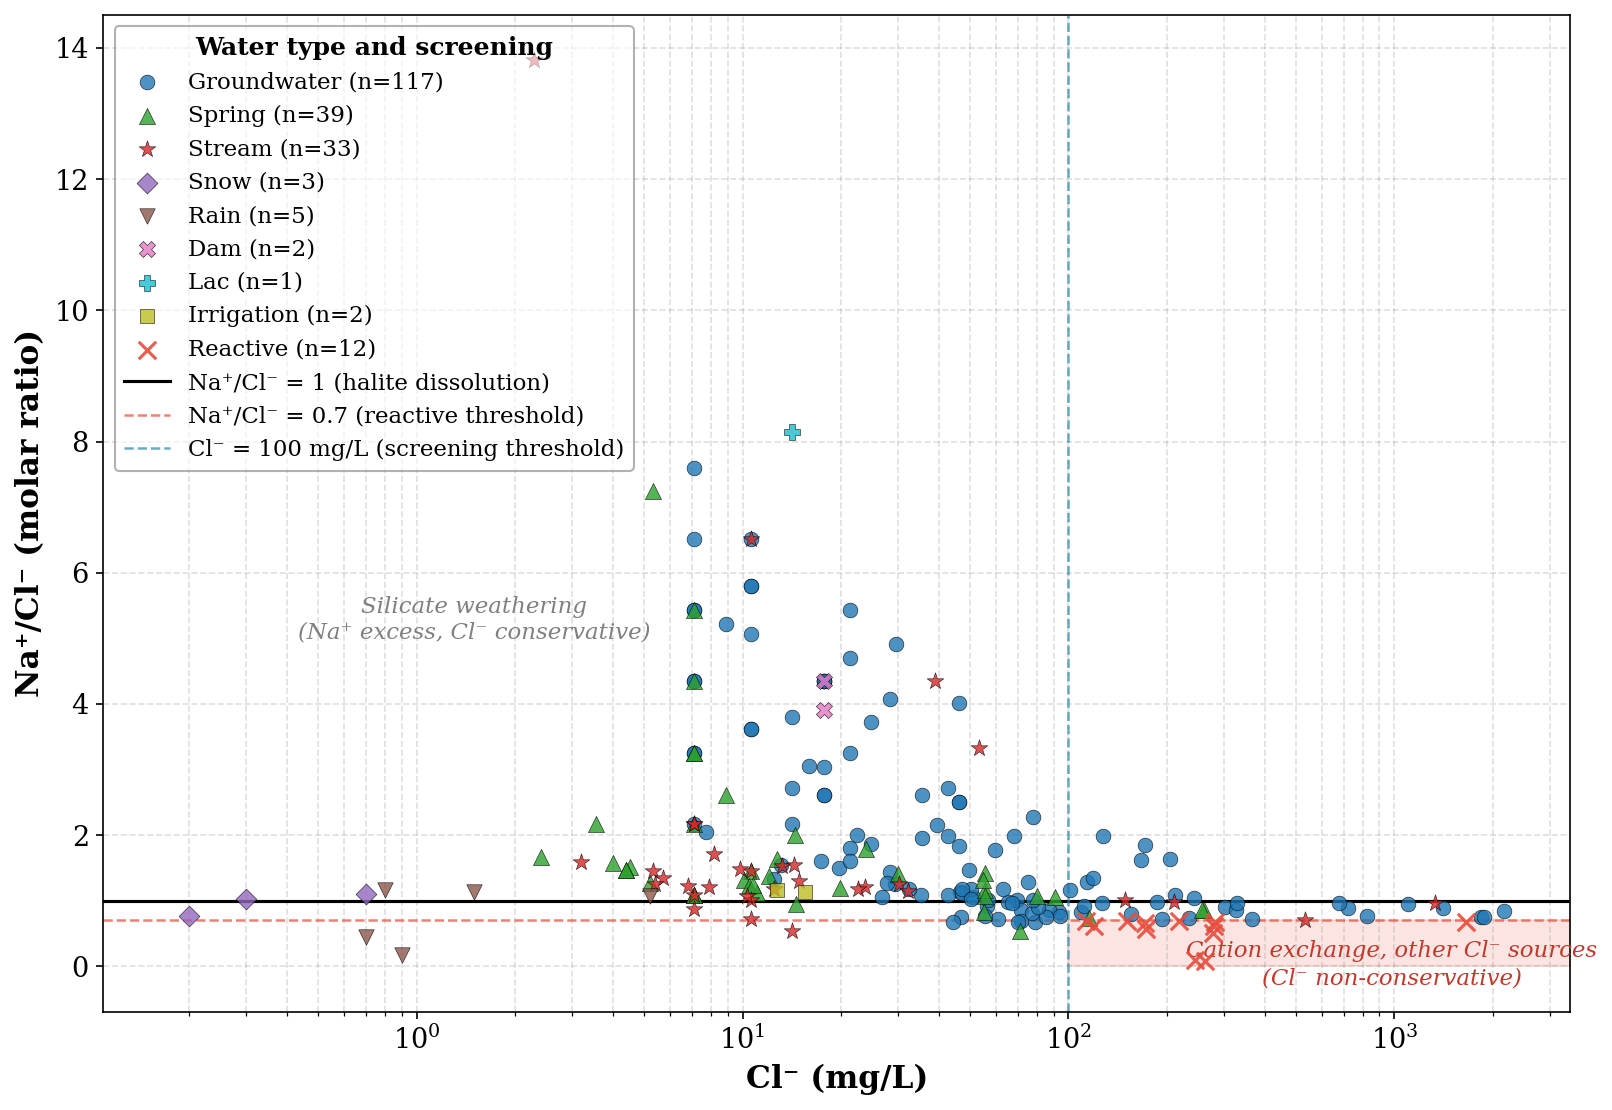

Saved: SM10_NaCl_screening.png


In [3]:
M_NA, M_CL = 22.99, 35.45
CL_MIN_SCREEN, NACL_MIN = 100.0, 0.7      # thresholds stated in the Methods

mask_chem = df["Na (mg/L)"].notna() & df[CL].notna()      # isotope dataset (345 samples) with Na+ and Cl-: 214, three of them with tritium only
df_chem = df.loc[mask_chem].copy()
df_chem["NaCl_ratio"] = (df_chem["Na (mg/L)"] / M_NA) / (df_chem[CL] / M_CL)
df_chem["reactive"] = (df_chem[CL] > CL_MIN_SCREEN) & (df_chem["NaCl_ratio"] < NACL_MIN)

n_total, n_reac = len(df_chem), int(df_chem["reactive"].sum())
print(f"Screened samples (isotope dataset with Na+ and Cl-): {n_total}, of which {int((df_chem[O18].notna()).sum())} with δ18O")
print(f"  conservative Cl- : {n_total - n_reac}")
print(f"  reactive Cl-     : {n_reac}   (Cl- > {CL_MIN_SCREEN:.0f} mg/L and Na+/Cl- < {NACL_MIN})")
print("  reactive by type :", df_chem.loc[df_chem["reactive"], "Type"].value_counts().to_dict())
assert (n_total, n_reac) == (214, 12), "screening counts differ from the article (214 screened, 12 reactive)"
print("Matches the article: 214 screened, 202 conservative, 12 reactive")

df["NaCl_ratio"] = np.nan
df.loc[mask_chem, "NaCl_ratio"] = df_chem["NaCl_ratio"].values
df["reactive_Cl"] = False
df.loc[mask_chem, "reactive_Cl"] = df_chem["reactive"].values

# ── Figure: Na+/Cl- ratio versus Cl- ─────────────────────────────────
LABEL_FS, TICK_FS, LEG_FS, LEG_TITLE_FS, ANNO_FS = 15, 13, 11, 12, 11
LEG_ALPHA = 0.6
TYPE_STYLE = {
    "Groundwater":    {"marker": "o", "color": "#1f77b4", "size": 35},
    "Spring":         {"marker": "^", "color": "#2ca02c", "size": 45},
    "Stream":         {"marker": "*", "color": "#d62728", "size": 55},
    "Snow":           {"marker": "D", "color": "#9467bd", "size": 35},
    "Rain":           {"marker": "v", "color": "#8c564b", "size": 40},
    "Dam":            {"marker": "X", "color": "#e377c2", "size": 45},
    "Lac":            {"marker": "P", "color": "#17becf", "size": 45},
    "Irrigation":     {"marker": "s", "color": "#bcbd22", "size": 35},
    "Canal (Zaraba)": {"marker": "h", "color": "#ff7f0e", "size": 45},
}

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.set_xscale("log")
df_cons, df_reac = df_chem[~df_chem["reactive"]], df_chem[df_chem["reactive"]]
for wtype, st in TYPE_STYLE.items():
    sub = df_cons[df_cons["Type"] == wtype]
    if len(sub) == 0:
        continue
    ax.scatter(sub[CL], sub["NaCl_ratio"], marker=st["marker"], c=st["color"], s=st["size"] + 15,
               edgecolors="black", linewidths=0.3, alpha=0.8, zorder=3, label=f"{wtype} (n={len(sub)})")
ax.scatter(df_reac[CL], df_reac["NaCl_ratio"], c="#E74C3C", s=70, marker="x", linewidths=1.5, alpha=0.9,
           zorder=4, label=f"Reactive (n={len(df_reac)})")
ax.axhline(1.0, color="k", ls="-", lw=1.5, zorder=2, label="Na⁺/Cl⁻ = 1 (halite dissolution)")
ax.axhline(NACL_MIN, color="#E74C3C", ls="--", lw=1.2, alpha=0.7, zorder=2, label=f"Na⁺/Cl⁻ = {NACL_MIN} (reactive threshold)")
ax.axvline(CL_MIN_SCREEN, color="#2E86AB", ls="--", lw=1.2, alpha=0.7, zorder=2, label=f"Cl⁻ = {CL_MIN_SCREEN:.0f} mg/L (screening threshold)")
ax.annotate("Silicate weathering" + chr(10) + "(Na⁺ excess, Cl⁻ conservative)", xy=(1.5, 5), fontsize=ANNO_FS,
            fontstyle="italic", color="gray", ha="center")
ax.text(980, 0.07, "Cation exchange, other Cl⁻ sources", fontsize=ANNO_FS, fontstyle="italic", color="#C0392B", ha="center", va="bottom")
ax.text(980, 0.07 - 0.08, "(Cl⁻ non-conservative)", fontsize=ANNO_FS, fontstyle="italic", color="#C0392B", ha="center", va="top")
ax.set_xlabel("Cl⁻ (mg/L)", fontsize=LABEL_FS, fontweight="bold")
ax.set_ylabel("Na⁺/Cl⁻ (molar ratio)", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(labelsize=TICK_FS)
ax.grid(True, ls="--", alpha=0.25, color="gray", which="both")
h, l = ax.get_legend_handles_labels()
leg = ax.legend(h, l, loc="upper left", fontsize=LEG_FS, framealpha=LEG_ALPHA, edgecolor="gray",
                title="Water type and screening", title_fontproperties={"weight": "bold", "size": LEG_TITLE_FS})
x_right = ax.get_xlim()[1]
ax.fill_between(np.logspace(2, np.log10(x_right * 10), 500), 0, NACL_MIN, alpha=0.15, color="#E74C3C", zorder=0)
ax.set_xlim(right=x_right)
fig.tight_layout()
fig.savefig(DIR_FIGURES / "SM10_NaCl_screening.png", dpi=DPI)
plt.show()
print("Saved: SM10_NaCl_screening.png")


### <font color='orange'> **4) Mixing targets: wells with δ¹⁸O and conservative Cl⁻** </font>

Following Bouimouass et al. (2024), the mixing model is applied to wells only. Springs, streams, snow and rain help to define the end-members but are not targets. The evaporation class of `02_isotopes.ipynb` is carried along so that evaporated wells among the targets can be counted; they stay in the model and their number is reported in the article.

In [4]:
mask_target = (df["Type"] == "Groundwater") & df[O18].notna() & df[CL].notna() & ~df["reactive_Cl"]
df_emma = df.loc[mask_target].reset_index(drop=True).copy()

print(f"Mixing targets (wells with δ18O and conservative Cl-): {len(df_emma)}")
print(f"  δ18O range : {df_emma[O18].min():.2f} to {df_emma[O18].max():.2f} permil")
print(f"  Cl- range  : {df_emma[CL].min():.1f} to {df_emma[CL].max():.1f} mg/L")
print(f"  evaporated among targets (02_isotopes class): {(df_emma['evap_group'] == 'evaporated').sum()}")
assert len(df_emma) == 148, "the article has 148 EMMA-ready wells"
print("Matches the article: 148 EMMA-ready wells")

df_emma.to_excel(DIR_INTERMED / "EMMA_ready_conservative.xlsx", index=False)
print("Saved: EMMA_ready_conservative.xlsx")


Mixing targets (wells with δ18O and conservative Cl-): 148
  δ18O range : -9.37 to -3.97 permil
  Cl- range  : 7.1 to 2176.1 mg/L
  evaporated among targets (02_isotopes class): 14
Matches the article: 148 EMMA-ready wells
Saved: EMMA_ready_conservative.xlsx


### <font color='orange'> **5) End-members from the data, with measured δ²H and d-excess** </font>

End-members are the extremes of the data cloud, as in Bouimouass et al. (2024):

| End-member | Represents | Selection rule |
|:--|:--|:--|
| **EM1 (MFR)** | mountain-front recharge | mean of the 5 most depleted δ¹⁸O stream and spring samples |
| **EM2 (regional MBR)** | regional mountain-block recharge | mean of the 3 highest-Cl⁻ wells |
| **EM3 (front-slope MBR)** | front-slope mountain-block recharge | mean of the 5 most enriched δ¹⁸O samples with Cl⁻ < 100 mg/L |

Each end-member carries the standard deviation of its defining samples (used by the Monte Carlo propagation). The δ²H of each end-member is the measured mean δ²H of the same defining samples, so the δ²H versus Cl⁻ diagram of Figure 11b rests on measured data. The d-excess of the defining samples tells whether an end-member is itself affected by evaporation.

In [5]:
pool = df.loc[df[O18].notna() & df[CL].notna()].copy()

em1_samples = pool[pool["Type"].isin(["Stream", "Spring"])].nsmallest(5, O18)
em2_samples = pool[pool["Type"] == "Groundwater"].nlargest(3, CL)
em3_samples = pool[pool["Type"].isin(["Groundwater", "Spring", "Rain"]) & (pool[CL] < 100)].nlargest(5, O18)

EM = {}
for key, label, smp in [("EM1", "EM1 (MFR)", em1_samples), ("EM2", "EM2 (Regional MBR)", em2_samples), ("EM3", "EM3 (Front-slope MBR)", em3_samples)]:
    EM[key] = {
        "label": label, "n": len(smp), "samples": smp["SampleID"].tolist(),
        "d18O": smp[O18].mean(), "d18O_sd": smp[O18].std(),
        "Cl": smp[CL].mean(), "Cl_sd": smp[CL].std(),
        "d2H": smp[H2].mean(), "d2H_sd": smp[H2].std(),                  # measured
        "dexcess": smp["d_excess"].mean(), "dexcess_min": smp["d_excess"].min(), "dexcess_max": smp["d_excess"].max(),
    }

print("End-members (mean ± SD of the defining samples)")
for key, e in EM.items():
    print(f"  {e['label']:22s} n={e['n']}  δ18O = {e['d18O']:6.2f} ± {e['d18O_sd']:.2f}   Cl- = {e['Cl']:7.1f} ± {e['Cl_sd']:.1f} mg/L   "
          f"δ2H = {e['d2H']:6.1f} ± {e['d2H_sd']:.1f}   "
          f"d-excess = {e['dexcess']:.1f} (range {e['dexcess_min']:.1f} to {e['dexcess_max']:.1f})")
    print(f"      defining samples: {', '.join(e['samples'])}")

# checks against the article (end-member δ18O and Cl- unchanged)
assert abs(EM["EM1"]["d18O"] + 9.07) < 0.01 and abs(EM["EM1"]["Cl"] - 6.3) < 0.1
assert abs(EM["EM2"]["d18O"] + 4.87) < 0.01 and abs(EM["EM2"]["Cl"] - 1969.0) < 0.1
assert abs(EM["EM3"]["d18O"] + 4.70) < 0.01 and abs(EM["EM3"]["Cl"] - 11.6) < 0.1
print("Matches the article: EM1 -9.07 / 6.3, EM2 -4.87 / 1969.0, EM3 -4.70 / 11.6")

# how many targets fall inside the triangle
tri = MplPath([(EM[k]["d18O"], EM[k]["Cl"]) for k in ("EM1", "EM2", "EM3")] + [(EM["EM1"]["d18O"], EM["EM1"]["Cl"])])
inside = tri.contains_points(np.column_stack([df_emma[O18].values, df_emma[CL].values]))
print(f"Targets inside the mixing triangle: {inside.sum()} of {len(df_emma)} ({100 * inside.mean():.1f} %)")


End-members (mean ± SD of the defining samples)
  EM1 (MFR)              n=5  δ18O =  -9.07 ± 0.27   Cl- =     6.3 ± 2.9 mg/L   δ2H =  -57.5 ± 2.8   d-excess = 15.0 (range 13.4 to 17.4)
      defining samples: S312, S313, S302, S299, S441
  EM2 (Regional MBR)     n=3  δ18O =  -4.87 ± 0.82   Cl- =  1969.0 ± 180.5 mg/L   δ2H =  -33.9 ± 6.4   d-excess = 5.1 (range -0.1 to 11.6)
      defining samples: S424, S460, S413
  EM3 (Front-slope MBR)  n=5  δ18O =  -4.70 ± 0.29   Cl- =    11.6 ± 10.4 mg/L   δ2H =  -25.3 ± 4.6   d-excess = 12.3 (range 10.2 to 15.1)
      defining samples: S388, S389, S294, S372, S352
Matches the article: EM1 -9.07 / 6.3, EM2 -4.87 / 1969.0, EM3 -4.70 / 11.6
Targets inside the mixing triangle: 132 of 148 (89.2 %)


### <font color='orange'> **6) Figure 11: mixing diagrams** </font>

- **(a)** δ¹⁸O versus Cl⁻: the mixing diagram used for the proportions. The dashed triangle joins the three end-members; valid wells fall inside it.
- **(b)** δ²H versus Cl⁻: the same diagram with the second isotope, end-member δ²H being the measured mean of the defining samples. It is a consistency check, not an independent validation, because δ²H and δ¹⁸O of meteoric waters are strongly correlated.

Wells outside the δ¹⁸O versus Cl⁻ triangle (16 of 148) have mixing fractions outside 0 to 1: they cannot be explained by the three end-members and are excluded from the averages; they are drawn hollow in both panels. The symbols are decided in panel (a), where the proportions are computed; the few wells that change side between the two panels lie at the edge of the mixing space.

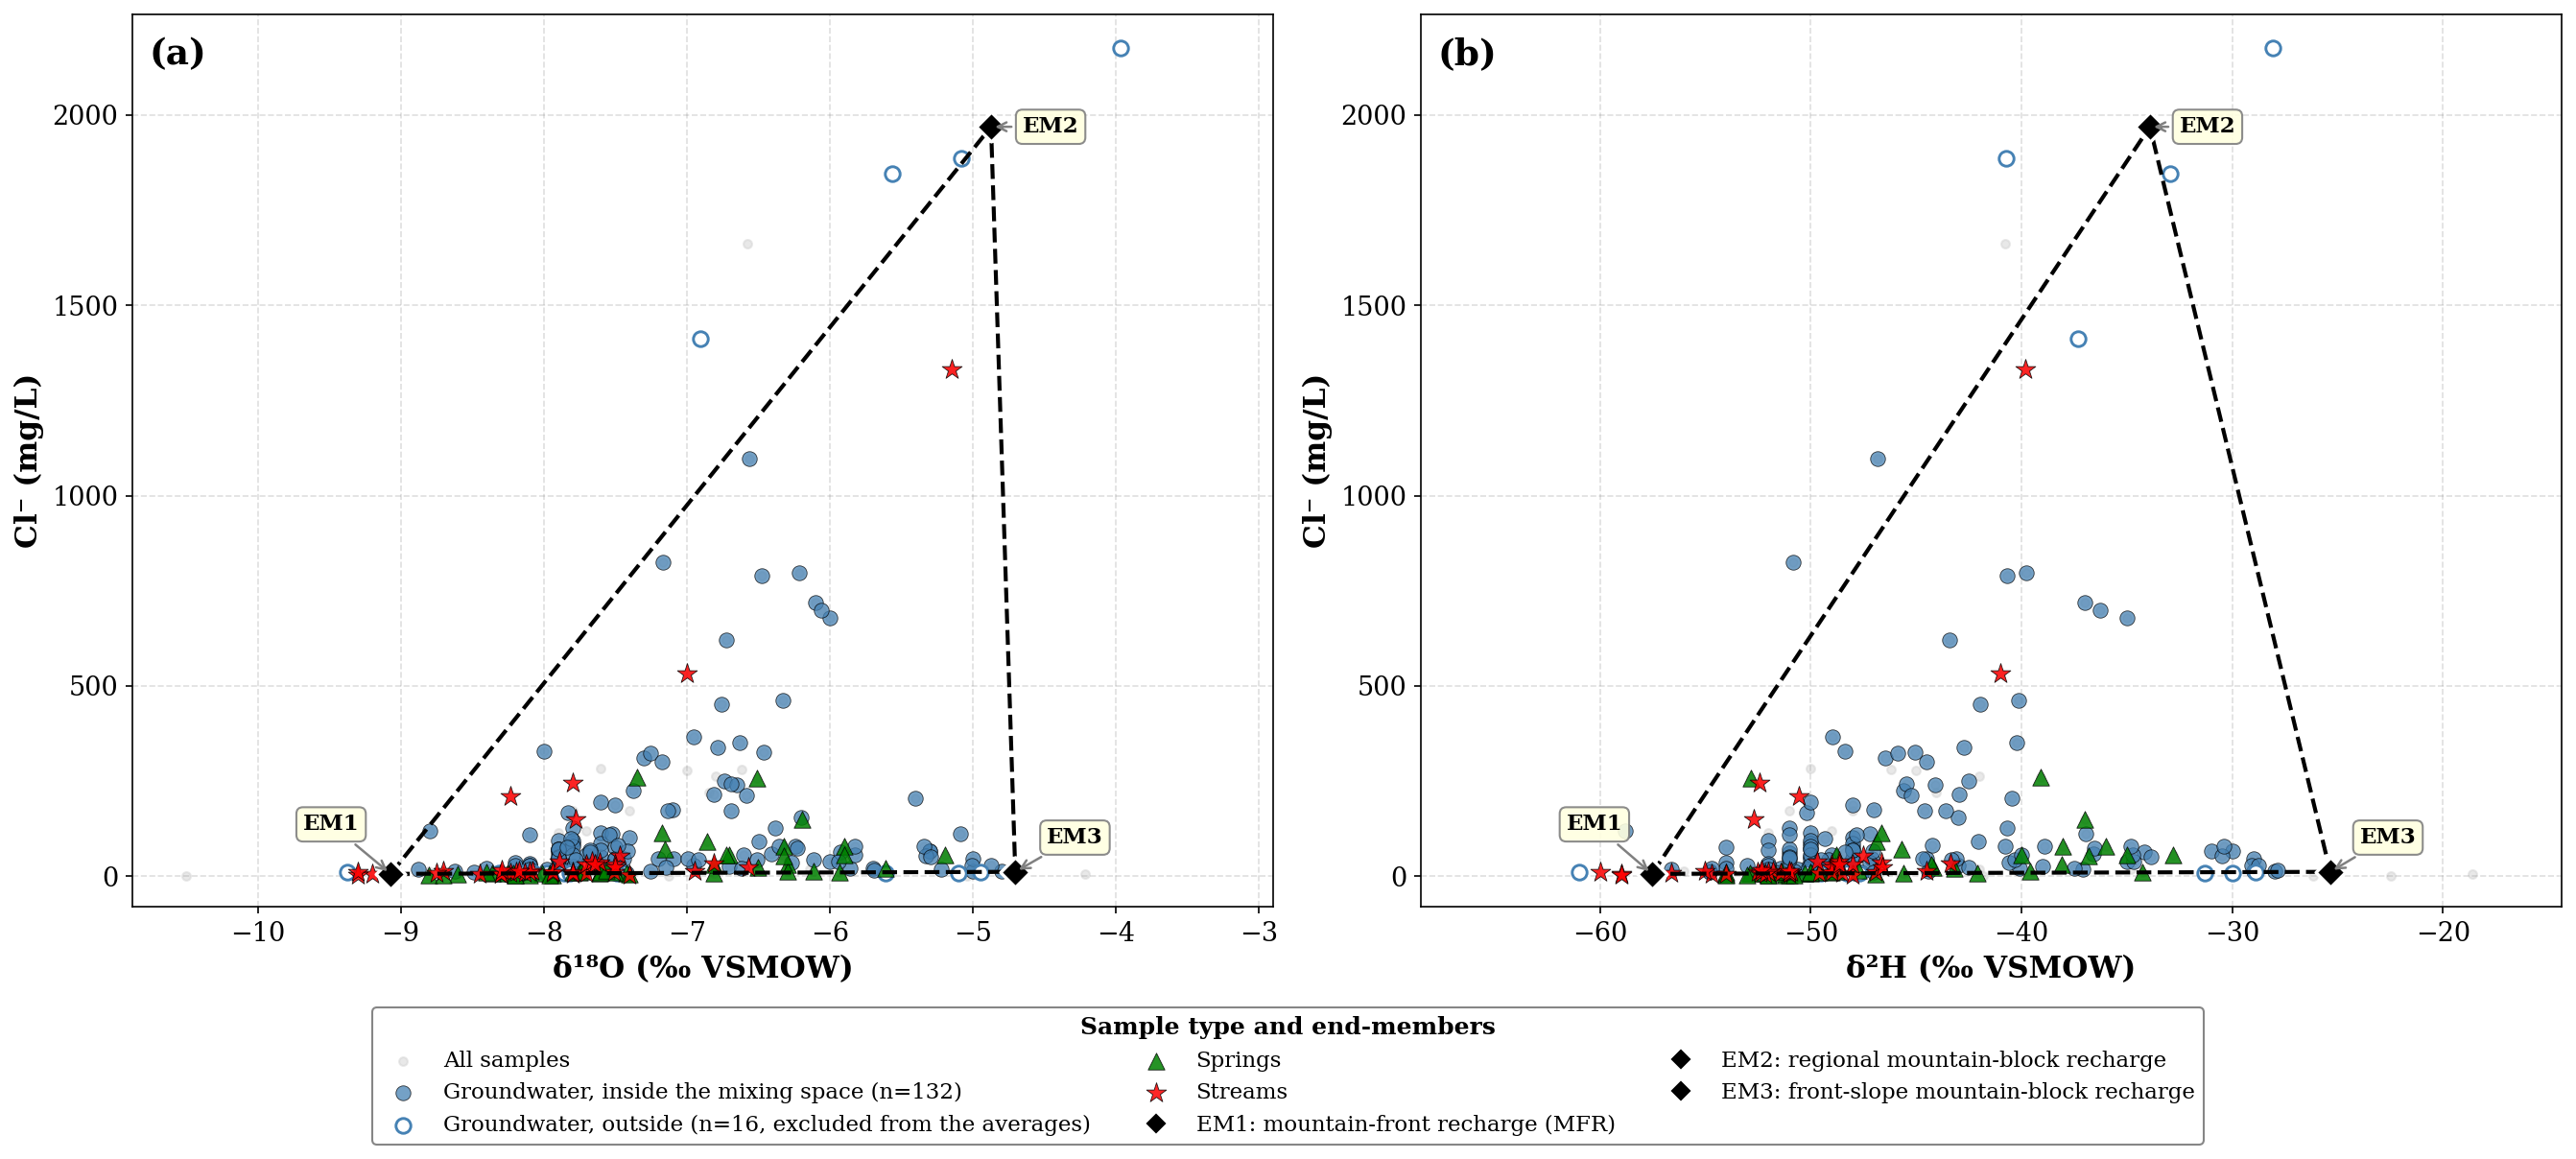

Saved: Figure11_d18O_d2H_vs_Cl_mixing_panel.png
Panel (b), measured δ2H: 130 of 148 targets inside the triangle (87.8 %); panel (a): 132 (89.2 %)


In [6]:
from matplotlib.lines import Line2D

LABEL_FS, TICK_FS, LEG_FS, LEG_TITLE_FS, EM_LBL_FS, PANEL_LBL_FS = 15, 13, 11, 12, 11, 18
LEG_ALPHA = 0.6

GW_STYLE     = dict(c="steelblue", marker="o", s=55, alpha=0.75, edgecolors="k", linewidths=0.4)
SPRING_STYLE = dict(c="green", marker="^", s=70, alpha=0.85, edgecolors="k", linewidths=0.4)
STREAM_STYLE = dict(c="red", marker="*", s=110, alpha=0.85, edgecolors="k", linewidths=0.4)
ALLBG_STYLE  = dict(c="lightgray", s=18, alpha=0.5)
EM_STYLE     = dict(c="black", marker="D", s=110, edgecolors="white", linewidths=1.6)

def draw_mixing_panel(ax, x_col, em_xkey, x_label, panel_letter, offset_map, x_pad_extra=1.0):
    """One mixing diagram: samples, end-members, triangle, labels, legend."""
    bg = pool[pool[x_col].notna()]
    ax.scatter(bg[x_col], bg[CL], zorder=1, label="All samples", **ALLBG_STYLE)
    ok = pd.Series(inside, index=df_emma.index)          # inside the δ18O-Cl triangle = valid mixing proportions
    ax.scatter(df_emma.loc[ok, x_col], df_emma.loc[ok, CL], zorder=3, label=f"Groundwater, inside the mixing space (n={ok.sum()})", **GW_STYLE)
    ax.scatter(df_emma.loc[~ok, x_col], df_emma.loc[~ok, CL], zorder=3, marker="o", s=55, facecolors="white",
               edgecolors="steelblue", linewidths=1.4, label=f"Groundwater, outside (n={(~ok).sum()}, excluded from the averages)")
    sp = pool[(pool["Type"] == "Spring") & pool[x_col].notna()]
    st = pool[(pool["Type"] == "Stream") & pool[x_col].notna()]
    ax.scatter(sp[x_col], sp[CL], zorder=4, label="Springs", **SPRING_STYLE)
    ax.scatter(st[x_col], st[CL], zorder=4, label="Streams", **STREAM_STYLE)
    for key in ("EM1", "EM2", "EM3"):
        ax.scatter(EM[key][em_xkey], EM[key]["Cl"], zorder=6, **EM_STYLE)
    ax.add_patch(Polygon([(EM[k][em_xkey], EM[k]["Cl"]) for k in ("EM1", "EM2", "EM3")],
                         fill=False, edgecolor="black", linestyle="--", linewidth=2, zorder=5))
    for key in ("EM1", "EM2", "EM3"):
        ox, oy, ha = offset_map[key]
        ax.annotate(key, xy=(EM[key][em_xkey], EM[key]["Cl"]), xytext=(EM[key][em_xkey] + ox, EM[key]["Cl"] + oy),
                    fontsize=EM_LBL_FS, fontweight="bold", ha=ha, va="center",
                    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gray", alpha=0.9),
                    arrowprops=dict(arrowstyle="->", color="gray", lw=1.2), zorder=7)
    xs = [EM[k][em_xkey] for k in EM]
    pad_x = 0.15 * (max(xs) - min(xs) + 1)
    ax.set_xlim(min(xs) - pad_x - x_pad_extra, max(xs) + pad_x + x_pad_extra)
    ax.set_ylim(-80, max(EM[k]["Cl"] for k in EM) * 1.15)
    ax.set_xlabel(x_label, fontsize=LABEL_FS, fontweight="bold")
    ax.set_ylabel("Cl⁻ (mg/L)", fontsize=LABEL_FS, fontweight="bold")
    ax.tick_params(labelsize=TICK_FS)
    ax.grid(True, ls="--", alpha=0.25, color="gray")
    h, l = ax.get_legend_handles_labels()
    h += [Line2D([0], [0], marker="D", color="black", markersize=8, linestyle="None", markeredgecolor="white",
                 markeredgewidth=1.0, label=f"{k}: {n}")
          for k, n in [("EM1", "mountain-front recharge (MFR)"), ("EM2", "regional mountain-block recharge"),
                       ("EM3", "front-slope mountain-block recharge")]]
    l += [x.get_label() for x in h[-3:]]
    # panel label inside the axes (top left), as in Figure 10
    ax.text(0.015, 0.975, f"({panel_letter})", transform=ax.transAxes, fontsize=PANEL_LBL_FS, fontweight="bold",
            va="top", ha="left", zorder=20)
    return h, l

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
offset_d18O = {"EM1": (-0.22, 130, "right"), "EM2": (0.22, 0, "left"), "EM3": (0.22, 90, "left")}
offset_d2H  = {"EM1": (-1.4, 130, "right"),  "EM2": (1.4, 0, "left"),  "EM3": (1.4, 90, "left")}
h, l = draw_mixing_panel(ax1, O18, "d18O", "δ¹⁸O (‰ VSMOW)", "a", offset_d18O, x_pad_extra=1.0)
draw_mixing_panel(ax2, H2,  "d2H",  "δ²H (‰ VSMOW)",  "b", offset_d2H,  x_pad_extra=6.0)
# one shared legend below the two panels (same symbols in both), so nothing covers the data or the triangle
fig.legend(h, l, loc="lower center", ncol=3, fontsize=LEG_FS, frameon=True, framealpha=0.95, edgecolor="gray",
           title="Sample type and end-members", title_fontproperties={"weight": "bold", "size": LEG_TITLE_FS},
           bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig(DIR_FIGURES / "Figure11_d18O_d2H_vs_Cl_mixing_panel.png", dpi=DPI)
plt.show()
print("Saved: Figure11_d18O_d2H_vs_Cl_mixing_panel.png")

# consistency check of panel (b): targets inside the triangle drawn with measured δ2H
tri_b = MplPath([(EM[k]["d2H"], EM[k]["Cl"]) for k in ("EM1", "EM2", "EM3")] + [(EM["EM1"]["d2H"], EM["EM1"]["Cl"])])
inside_b = tri_b.contains_points(np.column_stack([df_emma[H2].values, df_emma[CL].values]))
print(f"Panel (b), measured δ2H: {inside_b.sum()} of {len(df_emma)} targets inside the triangle ({100 * inside_b.mean():.1f} %); "
      f"panel (a): {inside.sum()} ({100 * inside.mean():.1f} %)")


### <font color='orange'> **7) Mixing proportions and validity** </font>

For each well with tracers (δ¹⁸O_s, Cl_s) the fractions R_a (EM1), R_b (EM2), R_c (EM3) solve the mass balance (Text SM3, Eq. SM3 to SM5):

$$R_a + R_b + R_c = 1, \qquad \delta_s = R_a\,\delta_a + R_b\,\delta_b + R_c\,\delta_c, \qquad C_s = R_a\,C_a + R_b\,C_b + R_c\,C_c$$

A well is **valid** when its three fractions lie between 0 and 1 (inside the triangle). The reported proportions are the unweighted means over the valid wells: they describe the sampled wells, not a flux-weighted recharge budget.

In [7]:
def emma_3em(d18O_s, Cl_s, em):
    """Three-end-member mass balance for one sample: fractions of EM1, EM2, EM3."""
    da, Ca = em["EM1"]["d18O"], em["EM1"]["Cl"]
    db, Cb = em["EM2"]["d18O"], em["EM2"]["Cl"]
    dc, Cc = em["EM3"]["d18O"], em["EM3"]["Cl"]
    denom_a = (da - dc) * (Cb - Cc) - (Ca - Cc) * (db - dc)
    denom_b = (db - dc) * (Ca - Cc) - (Cb - Cc) * (da - dc)
    if abs(denom_a) < 1e-12 or abs(denom_b) < 1e-12:
        return np.nan, np.nan, np.nan
    Ra = ((d18O_s - dc) * (Cb - Cc) - (Cl_s - Cc) * (db - dc)) / denom_a
    Rb = ((d18O_s - dc) * (Ca - Cc) - (Cl_s - Cc) * (da - dc)) / denom_b
    return Ra, Rb, 1.0 - Ra - Rb

res = df_emma.apply(lambda r: emma_3em(r[O18], r[CL], EM), axis=1, result_type="expand")
res.columns = ["Ra_MFR", "Rb_RegMBR", "Rc_FSMB"]
df_emma = pd.concat([df_emma.drop(columns=[c for c in res.columns if c in df_emma.columns]), res], axis=1)
df_emma["VALID"] = df_emma[["Ra_MFR", "Rb_RegMBR", "Rc_FSMB"]].apply(lambda r: bool(((r >= 0) & (r <= 1)).all()), axis=1)
df_emma["Dominant"] = df_emma[["Ra_MFR", "Rb_RegMBR", "Rc_FSMB"]].idxmax(axis=1).map(
    {"Ra_MFR": "MFR", "Rb_RegMBR": "Regional MBR", "Rc_FSMB": "Front-slope MBR"})

df_valid = df_emma[df_emma["VALID"]]
n_valid, n_invalid = len(df_valid), int((~df_emma["VALID"]).sum())
print(f"Valid wells: {n_valid}, invalid: {n_invalid} ({100 * n_valid / len(df_emma):.1f} % valid)")
for col, lab in [("Ra_MFR", "MFR"), ("Rb_RegMBR", "Regional MBR"), ("Rc_FSMB", "Front-slope MBR")]:
    print(f"  {lab:16s}: mean {df_valid[col].mean():.3f}, median {df_valid[col].median():.3f}, SD {df_valid[col].std():.3f}")
print(f"  total MBR (regional + front-slope): mean {(df_valid['Rb_RegMBR'] + df_valid['Rc_FSMB']).mean():.3f}")
print("  dominant component among valid wells:", df_valid["Dominant"].value_counts().to_dict())
print(f"  evaporated wells among valid: {(df_valid['evap_group'] == 'evaporated').sum()}, among invalid: {(df_emma.loc[~df_emma['VALID'], 'evap_group'] == 'evaporated').sum()}")
assert (n_valid, n_invalid) == (132, 16)
assert abs(df_valid["Ra_MFR"].mean() - 0.535) < 0.001 and abs(df_valid["Rb_RegMBR"].mean() - 0.064) < 0.001 and abs(df_valid["Rc_FSMB"].mean() - 0.401) < 0.001
print("Matches the article: 132 valid of 148; MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %")


Valid wells: 132, invalid: 16 (89.2 % valid)
  MFR             : mean 0.535, median 0.598, SD 0.219
  Regional MBR    : mean 0.064, median 0.028, SD 0.098
  Front-slope MBR : mean 0.401, median 0.330, SD 0.222
  total MBR (regional + front-slope): mean 0.465
  dominant component among valid wells: {'MFR': 88, 'Front-slope MBR': 39, 'Regional MBR': 5}
  evaporated wells among valid: 12, among invalid: 2
Matches the article: 132 valid of 148; MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %


### <font color='orange'> **8) Monte Carlo uncertainty (1,000 draws)** </font>

Each end-member is perturbed within its standard deviation (δ¹⁸O and Cl⁻) and the mass balance is solved again; the standard deviation of the 1,000 results is the standard error of each fraction (Phillips and Gregg, 2001; Liu and Yamanaka, 2012). Seed 42.

In [8]:
N_MC = 1000
rng = np.random.RandomState(42)
d18O_v, Cl_v = df_emma[O18].values, df_emma[CL].values
mc = np.full((3, len(df_emma), N_MC), np.nan)
for i in range(N_MC):
    em_p = {k: {"d18O": EM[k]["d18O"] + rng.normal(0, EM[k]["d18O_sd"]),
                "Cl": max(0.0, EM[k]["Cl"] + rng.normal(0, EM[k]["Cl_sd"]))} for k in ("EM1", "EM2", "EM3")}
    for j in range(len(df_emma)):
        mc[:, j, i] = emma_3em(d18O_v[j], Cl_v[j], em_p)
df_emma["SE_Ra"], df_emma["SE_Rb"], df_emma["SE_Rc"] = np.nanstd(mc[0], axis=1), np.nanstd(mc[1], axis=1), np.nanstd(mc[2], axis=1)
df_valid = df_emma[df_emma["VALID"]]
print(f"Monte Carlo done ({N_MC} draws). Mean standard errors over the valid wells: "
      f"MFR {df_valid['SE_Ra'].mean():.3f}, regional MBR {df_valid['SE_Rb'].mean():.3f}, front-slope MBR {df_valid['SE_Rc'].mean():.3f}")
print("Article: 0.052, 0.007, 0.053 (abstract: 53.5 ± 5.2 %, 6.4 ± 0.7 %, 40.1 ± 5.3 %)")


Monte Carlo done (1000 draws). Mean standard errors over the valid wells: MFR 0.051, regional MBR 0.007, front-slope MBR 0.053
Article: 0.052, 0.007, 0.053 (abstract: 53.5 ± 5.2 %, 6.4 ± 0.7 %, 40.1 ± 5.3 %)


### <font color='orange'> **9) Result figures: Figure SM12 (box plots) and Figure SM11 (mean contributions)** </font>

Distribution of the three fractions over the 132 valid wells (box plots, red dashed line = mean) and the mean apportionment (stacked bar). Both are unweighted means over the sampled wells.

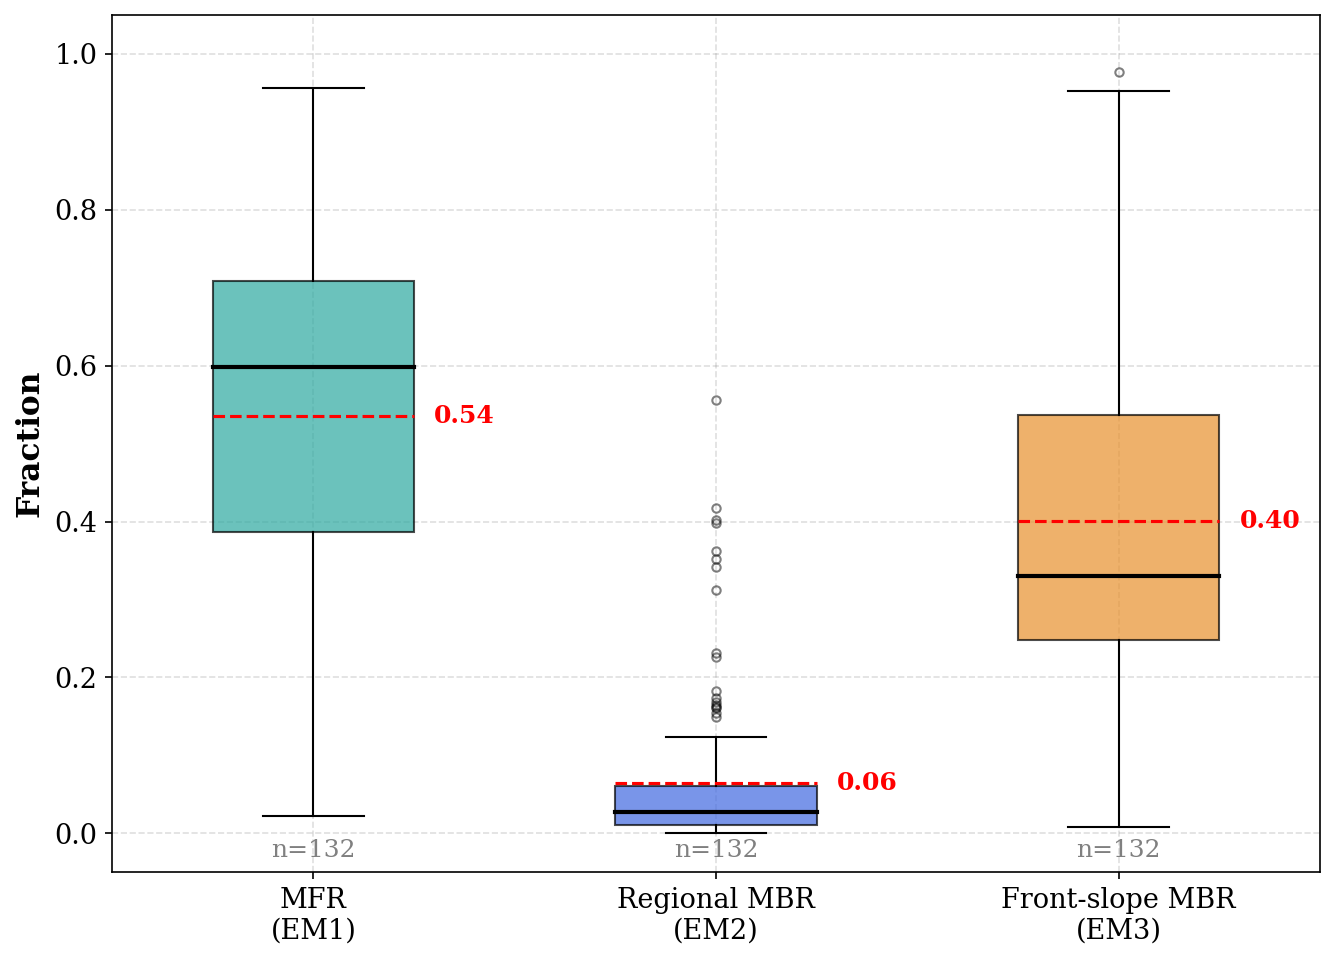

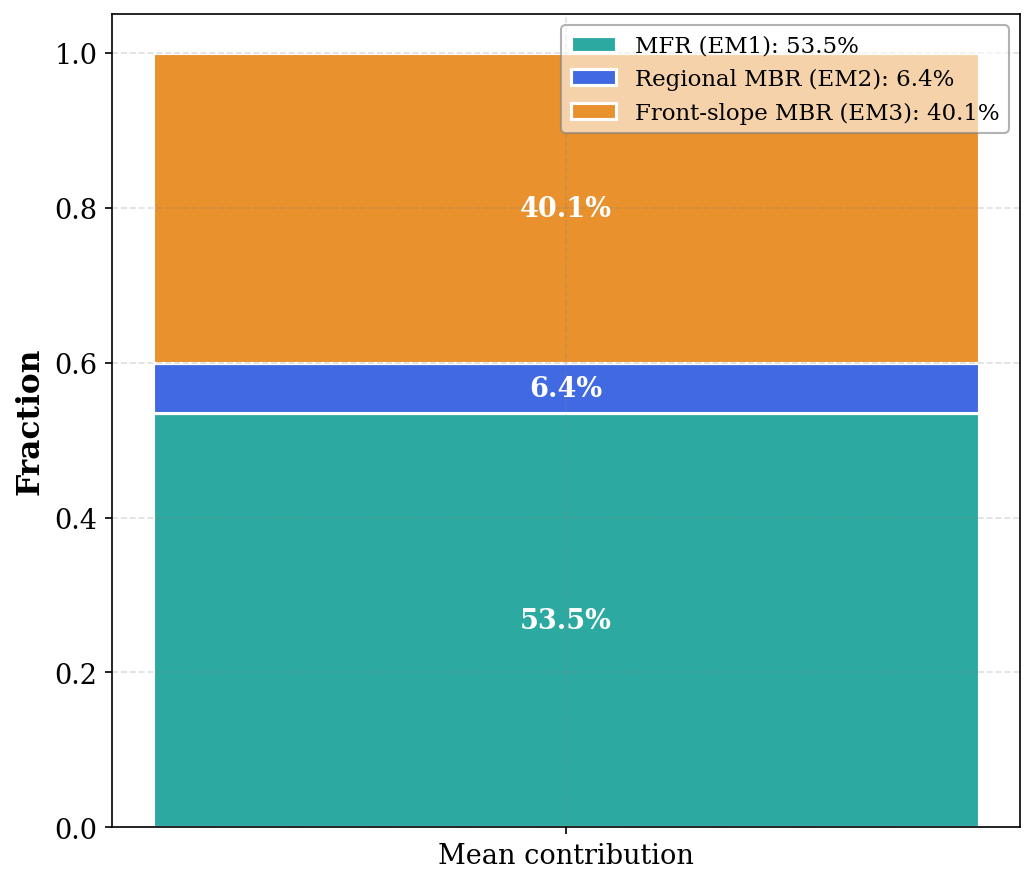

Saved: SM12_EMMA_boxplots.png, SM11_EMMA_stacked_bar.png


In [9]:
df_valid = df_emma[df_emma["VALID"]].copy()
LABEL_FS, TICK_FS, ANNO_FS, BAR_FS = 15, 13, 12, 13
box_data = [df_valid["Ra_MFR"].values, df_valid["Rb_RegMBR"].values, df_valid["Rc_FSMB"].values]
box_labels = ["MFR" + chr(10) + "(EM1)", "Regional MBR" + chr(10) + "(EM2)", "Front-slope MBR" + chr(10) + "(EM3)"]
colors = ["#2ca9a0", "#4169e1", "#e8912d"]

fig, ax = plt.subplots(figsize=(9, 6.5))
bp = ax.boxplot(box_data, labels=box_labels, patch_artist=True, widths=0.5,
                medianprops=dict(color="black", lw=2), flierprops=dict(marker="o", markersize=4, alpha=0.5))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(box_data):
    ax.hlines(d.mean(), i + 0.75, i + 1.25, colors="red", linestyles="dashed", linewidths=1.5, zorder=4)
    ax.text(i + 1.30, d.mean(), f"{d.mean():.2f}", va="center", fontsize=ANNO_FS, color="red", fontweight="bold")
    ax.text(i + 1, -0.03, f"n={len(d)}", ha="center", fontsize=ANNO_FS, color="gray")
ax.set_ylabel("Fraction", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(labelsize=TICK_FS)
ax.set_ylim(-0.05, 1.05)
fig.tight_layout()
fig.savefig(DIR_FIGURES / "SM12_EMMA_boxplots.png", dpi=DPI)
plt.show()

means = [d.mean() for d in box_data]
labels_bar = ["MFR (EM1)", "Regional MBR (EM2)", "Front-slope MBR (EM3)"]
fig, ax = plt.subplots(figsize=(7, 6))
bottom = 0.0
for m, lab, col in zip(means, labels_bar, colors):
    ax.bar("Mean contribution", m, bottom=bottom, color=col, edgecolor="white", linewidth=1.5, label=f"{lab}: {m:.1%}")
    ax.text(0, bottom + m / 2, f"{m:.1%}", ha="center", va="center", fontsize=BAR_FS, fontweight="bold", color="white")
    bottom += m
ax.set_ylabel("Fraction", fontsize=LABEL_FS, fontweight="bold")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", framealpha=LEG_ALPHA, edgecolor="gray", fontsize=11)
ax.tick_params(labelsize=TICK_FS)
fig.tight_layout()
fig.savefig(DIR_FIGURES / "SM11_EMMA_stacked_bar.png", dpi=DPI)
plt.show()
print("Saved: SM12_EMMA_boxplots.png, SM11_EMMA_stacked_bar.png")


### <font color='orange'> **10) Tritium consistency check (Figure SM13, only if ³H is available)** </font>

³H of the valid wells grouped by dominant component. Expected tendency: higher ³H where MFR dominates (recent recharge), lower where regional MBR dominates (longer flow paths). With 25 wells and a weak relation this is a qualitative consistency check only; no residence time is computed.

In [10]:
if not HAS_3H or df_emma["3H_value"].notna().sum() == 0:
    print("Tritium not available in the shared data file: section skipped (Figure SM13 not produced).")
    lr3 = None
else:
    df_3h = df_emma[df_emma["VALID"] & df_emma["3H_value"].notna()].copy()
    print(f"Valid wells with tritium: {len(df_3h)}")
    order = ["MFR", "Regional MBR", "Front-slope MBR"]
    palette = {"MFR": "#2ca9a0", "Regional MBR": "#4169e1", "Front-slope MBR": "#e8912d"}
    for dom in order:
        sub = df_3h[df_3h["Dominant"] == dom]
        print(f"  {dom:16s}: n={len(sub):2d}, median {sub['3H_value'].median():.2f} TU" if len(sub) else f"  {dom:16s}: no samples")

    # relation between the MFR fraction and tritium (linear, for the record)
    from scipy import stats as _st
    lr3 = _st.linregress(df_3h["Ra_MFR"], df_3h["3H_value"])
    print(f"  3H versus MFR fraction: r2 = {lr3.rvalue**2:.2f}, p = {lr3.pvalue:.2f}  (weak; qualitative check only)")

    existing = [g for g in order if g in df_3h["Dominant"].values]
    fig, ax = plt.subplots(figsize=(9, 6.5))
    sns.boxplot(data=df_3h, x="Dominant", y="3H_value", order=existing, palette=palette, width=0.5, ax=ax)
    sns.stripplot(data=df_3h, x="Dominant", y="3H_value", order=existing, color="black", size=5, alpha=0.5, jitter=True, ax=ax)
    ax.set_xlabel("Dominant recharge component", fontsize=LABEL_FS, fontweight="bold")
    ax.set_ylabel("³H (TU)", fontsize=LABEL_FS, fontweight="bold")
    ax.tick_params(labelsize=TICK_FS)
    fig.tight_layout()
    fig.savefig(DIR_FIGURES / "SM13_3H_by_dominant_source.png", dpi=DPI)
    plt.show()
    print("Saved: SM13_3H_by_dominant_source.png")


Tritium not available in the shared data file: section skipped (Figure SM13 not produced).


### <font color='orange'> **11) Export and summary** </font>

`outputs/tables/EMMA_results.xlsx` (sheets Valid_EMMA, Invalid_EMMA, EndMembers, Summary; the Valid_EMMA sheet is the input of the Figure 12 map) and `outputs/tables/emma_summary.txt`.

In [11]:
df_valid_out, df_invalid_out = df_emma[df_emma["VALID"]].copy(), df_emma[~df_emma["VALID"]].copy()
em_export = pd.DataFrame([{
    "End-member": e["label"], "n_defining": e["n"], "defining_samples": ", ".join(e["samples"]),
    "d18O_mean": e["d18O"], "d18O_SD": e["d18O_sd"], "Cl_mean_mg_L": e["Cl"], "Cl_SD_mg_L": e["Cl_sd"],
    "d2H_mean_measured": e["d2H"], "d2H_SD_measured": e["d2H_sd"],
    "dexcess_mean": e["dexcess"], "dexcess_min": e["dexcess_min"], "dexcess_max": e["dexcess_max"]} for e in EM.values()])
summary = pd.DataFrame({"Metric": ["EMMA-ready wells", "Valid", "Invalid", "Valid %", "Mean MFR", "Mean regional MBR", "Mean front-slope MBR",
                                   "Mean total MBR", "Mean SE MFR", "Mean SE regional MBR", "Mean SE front-slope MBR",
                                   "Screened for Na/Cl", "Conservative", "Reactive"],
                        "Value": [len(df_emma), len(df_valid_out), len(df_invalid_out), f"{100 * len(df_valid_out) / len(df_emma):.1f}",
                                  f"{df_valid_out['Ra_MFR'].mean():.4f}", f"{df_valid_out['Rb_RegMBR'].mean():.4f}", f"{df_valid_out['Rc_FSMB'].mean():.4f}",
                                  f"{(df_valid_out['Rb_RegMBR'] + df_valid_out['Rc_FSMB']).mean():.4f}",
                                  f"{df_valid_out['SE_Ra'].mean():.4f}", f"{df_valid_out['SE_Rb'].mean():.4f}", f"{df_valid_out['SE_Rc'].mean():.4f}",
                                  n_total, n_total - n_reac, n_reac]})
out_path = DIR_TABLES / "EMMA_results.xlsx"
with pd.ExcelWriter(out_path, engine="openpyxl") as w:
    df_valid_out.to_excel(w, sheet_name="Valid_EMMA", index=False)
    df_invalid_out.to_excel(w, sheet_name="Invalid_EMMA", index=False)
    em_export.to_excel(w, sheet_name="EndMembers", index=False)
    summary.to_excel(w, sheet_name="Summary", index=False)

lines = ["EMMA summary (05_EMMA/01_EMMA.ipynb)",
         f"Na/Cl screening on the isotope dataset: {n_total} screened (Cl- > {CL_MIN_SCREEN:.0f} mg/L and Na/Cl < {NACL_MIN}), {n_total - n_reac} conservative, {n_reac} reactive",
         f"Mixing targets: {len(df_emma)} wells; valid {len(df_valid_out)} ({100 * len(df_valid_out) / len(df_emma):.1f} %), invalid {len(df_invalid_out)}",
         f"Means over valid wells: MFR {100 * df_valid_out['Ra_MFR'].mean():.1f} %, regional MBR {100 * df_valid_out['Rb_RegMBR'].mean():.1f} %, "
         f"front-slope MBR {100 * df_valid_out['Rc_FSMB'].mean():.1f} %, total MBR {100 * (df_valid_out['Rb_RegMBR'] + df_valid_out['Rc_FSMB']).mean():.1f} %",
         f"Monte Carlo SE: {100 * df_valid_out['SE_Ra'].mean():.1f}, {100 * df_valid_out['SE_Rb'].mean():.1f}, {100 * df_valid_out['SE_Rc'].mean():.1f} %",
         "Dominant component among valid wells: " + str(df_valid_out["Dominant"].value_counts().to_dict()),
         f"Evaporated wells (02_isotopes class): {(df_valid_out['evap_group'] == 'evaporated').sum()} among valid, {(df_invalid_out['evap_group'] == 'evaporated').sum()} among invalid",
         ""]
for e in EM.values():
    lines.append(f"{e['label']}: n={e['n']} ({', '.join(e['samples'])}); d18O {e['d18O']:.2f} ± {e['d18O_sd']:.2f}; Cl {e['Cl']:.1f} ± {e['Cl_sd']:.1f} mg/L; "
                 f"d2H {e['d2H']:.1f} ± {e['d2H_sd']:.1f}; d-excess {e['dexcess']:.1f} (range {e['dexcess_min']:.1f} to {e['dexcess_max']:.1f})")
lines.append(f"Panel (b) with measured d2H: {inside_b.sum()} of {len(df_emma)} wells inside the triangle ({100 * inside_b.mean():.1f} %)")
if lr3 is not None:
    lines.append(f"Tritium: {len(df_3h)} valid wells; 3H versus MFR fraction r2 = {lr3.rvalue**2:.2f}")
report = chr(10).join(lines)
with open(DIR_TABLES / "emma_summary.txt", "w", encoding="utf-8") as fh:
    fh.write(report)
print(report)
print()
print("Saved: outputs/tables/EMMA_results.xlsx, emma_summary.txt")

# ── Check against the article ────────────────────────────────────────
assert (len(df_emma), len(df_valid_out)) == (148, 132)
assert tuple(round(100 * df_valid_out[c].mean(), 1) for c in ["Ra_MFR", "Rb_RegMBR", "Rc_FSMB"]) == (53.5, 6.4, 40.1)
assert np.allclose([100 * df_valid_out[c].mean() for c in ["SE_Ra", "SE_Rb", "SE_Rc"]], [5.2, 0.7, 5.3], atol=0.15)
assert abs(EM["EM3"]["dexcess"] - 12.3) < 0.1
print("✓ Matches the article: 148 wells, 132 valid (89.2 %); MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %; Monte Carlo SE 5.2 / 0.7 / 5.3 %; EM3 d-excess 12.3 permil.")


EMMA summary (05_EMMA/01_EMMA.ipynb)
Na/Cl screening on the isotope dataset: 214 screened (Cl- > 100 mg/L and Na/Cl < 0.7), 202 conservative, 12 reactive
Mixing targets: 148 wells; valid 132 (89.2 %), invalid 16
Means over valid wells: MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %, total MBR 46.5 %
Monte Carlo SE: 5.1, 0.7, 5.3 %
Dominant component among valid wells: {'MFR': 88, 'Front-slope MBR': 39, 'Regional MBR': 5}
Evaporated wells (02_isotopes class): 12 among valid, 2 among invalid

EM1 (MFR): n=5 (S312, S313, S302, S299, S441); d18O -9.07 ± 0.27; Cl 6.3 ± 2.9 mg/L; d2H -57.5 ± 2.8; d-excess 15.0 (range 13.4 to 17.4)
EM2 (Regional MBR): n=3 (S424, S460, S413); d18O -4.87 ± 0.82; Cl 1969.0 ± 180.5 mg/L; d2H -33.9 ± 6.4; d-excess 5.1 (range -0.1 to 11.6)
EM3 (Front-slope MBR): n=5 (S388, S389, S294, S372, S352); d18O -4.70 ± 0.29; Cl 11.6 ± 10.4 mg/L; d2H -25.3 ± 4.6; d-excess 12.3 (range 10.2 to 15.1)
Panel (b) with measured d2H: 130 of 148 wells inside the triangle (87.

---
**Figures:** Figure 11, SM10, SM11, SM12 in `outputs/figures/` (SM13 needs the tritium data)

**Tables:** `outputs/tables/EMMA_results.xlsx`, `outputs/tables/emma_summary.txt`

**Next:** `02_EMMA_sensitivity.ipynb` (scenarios S1-S5; Table SM2, Figure SM14)